# 04. 위험도 2축 모델 — 정답 없이 만든 행동 고립 × 사회경제 취약 위험도와 사전 등록 검증


| 단계 | 노트북 | 질문 |
|---|---|---|
| 00 | 프로젝트 개요 | 무엇을, 왜, 어떤 순서로 하는가 |
| 01 | 데이터 준비 · 품질 점검 | 받은 데이터를 그대로 믿고 써도 되는가 |
| 02 | 탐색 분석 — 고립 신호 | 데이터에서 연령·성별·지역별 고립 신호 후보가 보이는가 |
| 03 | 외부 데이터 결합 · 검증 | 그 신호를 공식 기준·외부 요인·정답 데이터로 검증하면 무엇이 남는가 |
| 04 | **위험도 2축 모델 (주 모델)** | 정답 없이 만든 '행동 고립 × 사회경제 취약' 위험도가 실행 전에 정한 독립 기준을 통과하는가 |
| 05 | 복지자원 매핑 | 위험 유형 × 생애단계에 연계할 복지서비스가 실제로 있는가 |
| 06 | AI 에이전트 설계 | 탐지→판단→원인→추천→우선 대상을 어떻게 운영하고, 실제 고립과 어떻게 연결하는가 |
| 부록 A | 학습형 비교 모델 (이전 04) | SKT 정답으로 학습하면 어디까지 맞히는가 · 실시간 단계 조정 규칙 T |
| 부록 B | 지수형 첫 검증 (이전 04b) | 정답 없이 만든 지수가 학습형만큼 맞히고 독립 지표와도 맞는가 |

> **이전 단계에서 온 것**: 03의 공식 기준과 날씨 보정, 부록 A·B의 결론(학습형은 SKT 순환·강남 편중, 지수형은 정답 없이도 같은 성능이지만 동 규모 편향과 취약형 누락)  
> **이 노트북에서 할 것**: SK 행동(방문객·규모 보정)과 행정 취약 지표로 두 축을 만들고, 실행 전에 고정한 독립 기준으로 두 지역을 각각 검증한 뒤, 유형·5단계·우선 대상을 확정합니다.  
> **다음 단계로 넘길 것**: 동 × 성 × 연령별 위험 유형·5단계·주요 요인(outputs/위험도_2축_강남_춘천_동x성x연령.csv) → 05 유형별 복지자원 매핑, 06 에이전트 설계

**위험도의 구조 (2축 지수형)** — SKT 정답으로 학습하지 않고, 이론으로 정한 지표를 두 지역에 같은 규칙으로 적용합니다.

| 축 | 질문 | 담당 데이터 | 기호 |
|---|---|---|---|
| 기본 위험 | 이 성·연령은 원래 얼마나 고립되기 쉬운가 | 외부: 통계청 사회적 고립도 | **B** |
| **행동 고립** | 이 동·집단은 동네에 갇힌 듯 머무는가 | **제공: SK 유동인구** (방문객·규모 보정) | **H** |
| **사회경제 취약** | 이 동·집단은 혼자 살거나 경제적으로 어려운가 | 외부: 주민등록 1인 세대, 기초생활수급자·기초연금 | **V** |
| 집단 행동 | 이 성·연령 집단은 생활 소비가 위축됐는가 | **제공: 신한카드** | **C** |
| 시점 신호 | 지금 평소보다 활동이 지속적으로 줄었는가 | **제공: 신한카드 일별** + 외부: 기상청 보정 | **T** (부록 A 9절의 규칙 그대로) |

**우선순위 점수 = B × H배수 × V배수 × C** → 두 축의 높고 낮음으로 **4가지 유형**(이중 위험·행동형·취약형·저위험) → 공식 고립률(33%)에 맞춘 **5단계**

| 이전 모델과의 관계 | |
|---|---|
| 부록 A (학습형) | 강남 SKT 정답으로 가중치를 학습한 이전 주 모델. 비교 기준으로 남깁니다. |
| 부록 B (지수형 첫 검증) | 정답 없이 만든 지수가 학습형만큼 맞히고, 출처가 다른 지표와도 맞는다는 것을 처음 확인했습니다. 이 노트북은 그 지수를 보완해 주 모델로 확정합니다. |

In [1]:
import warnings, json, re, glob, os; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, openpyxl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr, rankdata
from sklearn.linear_model import LinearRegression
plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.titlesize': 11.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220); pd.set_option('display.float_format', '{:,.3f}'.format)
DATA, EXT, OUTD = Path('csv'), Path('external'), Path('outputs')
MAIN = ['서울 강남구', '강원 춘천시']; C_ = {'서울 강남구': '#2a78d6', '강원 춘천시': '#eb6834'}
INK, INK2, GRAY = '#0b0b0b', '#52514e', '#b5b4ae'
TYPE_C = {'이중 위험': '#c43a39', '행동형': '#eb6834', '취약형': '#1c5cab', '저위험': '#e6e5e1'}
AGE5 = ['20대', '30대', '40대', '50대', '60대+']; SEX = ['남성', '여성']; K3 = ['SGIS코드', '성별', '연령5']
def a5(a): return '60대+' if a >= 60 else (f'{a // 10 * 10}대' if a >= 20 else None)
PROTO = json.load(open(OUTD / '검증프로토콜_사전등록.json', encoding='utf-8'))     # 실행 전에 고정한 검증 기준
FROZEN = json.load(open(OUTD / '모델설정_동결.json', encoding='utf-8'))            # B·C·5단계는 이전 동결값 그대로
print('사전 등록:', PROTO['작성'])

사전 등록: 2026-10-13, 2축 모델(04) 실행 전에 고정. 이후 수정하지 않음


## 1. 데이터 준비 — 주민등록을 분석 기간에 맞는 시점으로 교체

> **왜** 이전 모델은 2026.9 주민등록을 써서 분석 기간(2025 하반기)과 1년 어긋났습니다(P6).  
> **결과** 주민등록 2024.12·2025.12(행정동 × 성 × 연령, 인구·1인세대)를 47개 동 모두 연결했습니다. 행동 축에는 2025.12, 취약 축에는 2024.12를 씁니다.


- **주민등록 (행안부, 행정동 × 성 × 10세 연령)**: 2024.12와 2025.12를 모두 씁니다.
  - 행동 축(SK 유동 ÷ 주민)에는 **2025.12** — SK 데이터 기간(2025.7~12)의 끝 시점
  - 취약 축(수급자 ÷ 인구)에는 **2024.12** — 수급자·춘천 연보와 같은 시점
  - 이전 모델은 2026.9 주민등록을 썼습니다(시점 불일치, 과제 P6).
- **SK 유동인구**: 집단(동 × 성 × 연령)별 월 유동, 동별 시간대 유동
- **신한카드**: 집단 행동 C (부록 A와 같은 정의·가중치)

In [2]:
%%time
CODES = pd.read_csv(EXT / 'codes/읍면동_코드대응표_강남_춘천.csv', dtype=str)
NAME = dict(zip(CODES['SGIS코드'], CODES['읍면동명'])); K2S = dict(zip(CODES['행정기관코드'], CODES['SGIS코드']))
def mois(kind, ymd):
    d = pd.read_csv(EXT / f'mois/행정동_성연령별_{kind}_{ymd}.csv', encoding='cp949', dtype=str)
    d.index = pd.Index(d['행정구역'].str.extract(r'\((\d{10})\)')[0].map(K2S), name='SGIS코드')
    d = d[d.index.notna()].drop(columns='행정구역').apply(lambda s: pd.to_numeric(s.str.replace(',', '')))
    d.columns = [c.split('_', 1)[1] for c in d.columns]                  # '계_총인구수', '남_0~9세' …
    return d
def by_cell(d):                                                          # 동 × 성 × 연령5 (10대 이하 제외, 60대+ 합침)
    cols = [c for c in d.columns if re.match(r'^(남|여)_\d', c)]
    L = d[cols].stack().rename('n').reset_index(); L.columns = ['SGIS코드', 'col', 'n']
    L['성별'] = L['col'].str[0].map({'남': '남성', '여': '여성'}); L['연령5'] = L['col'].str.extract(r'_(\d+)')[0].astype(int).map(a5)
    return L.dropna(subset=['연령5']).groupby(K3)['n'].sum()
POP = {y: mois('주민등록인구', y) for y in ['20241231', '20251231']}
ONE = {y: mois('1인세대수', y) for y in ['20241231', '20251231']}
assert all(len(d) == 47 for d in list(POP.values()) + list(ONE.values()))
for y in POP:
    assert (by_cell(ONE[y]) <= by_cell(POP[y])).all()                    # 1인세대 ≤ 인구 (모든 칸)
print('주민등록 47개 동 연결 완료 | 동 인구 합계:', {y: POP[y].join(CODES.set_index('SGIS코드')['지역']).groupby('지역')['계_총인구수'].sum().to_dict() for y in POP})

# --- SK 유동인구
age = pd.read_csv(DATA / 'SK_유동인구_성연령.csv', dtype={'기준년월': str, '소지역코드': str})
age['SGIS코드'] = age['소지역코드'].str[:8]; age = age[age['SGIS코드'].isin(CODES['SGIS코드'])]
MC = [c for c in age.columns if c.startswith('남자')]; FC = [c for c in age.columns if c.startswith('여자')]
SKA = ['10대', '20대', '30대', '40대', '50대', '60대+']
skl = age.groupby(['SGIS코드', '기준년월'])[MC + FC].sum().stack().rename('유동').reset_index()
skl['성별'] = np.where(skl['level_2'].str.startswith('남자'), '남성', '여성'); skl['연령5'] = skl['level_2'].map(dict(zip(MC + FC, SKA * 2)))
skl = skl[skl['연령5'] != '10대']
MON = skl.groupby(K3 + ['기준년월'])['유동'].sum().unstack()                 # 집단 × 월
tm = pd.read_csv(DATA / 'SK_유동인구_시간대.csv', dtype={'기준년월': str, '소지역코드': str})
tm['SGIS코드'] = tm['소지역코드'].str[:8]; tm = tm[tm['SGIS코드'].isin(CODES['SGIS코드'])]
TM = [f'유동인구수_{h:02d}시간대' for h in range(24)]; tmS = tm.groupby('SGIS코드')[TM].sum()
DAYNIGHT = (tmS[TM[9:18]].sum(axis=1) / 9) / (tmS[TM[:6]].sum(axis=1) / 6)      # 주간/야간 유동 비 = 상업·업무지 정도

U = MON.mean(axis=1).rename('집단유동').reset_index().merge(CODES[['SGIS코드', '행정기관코드', '지역', '유형']], on='SGIS코드')
U['읍면동명'] = U['SGIS코드'].map(NAME); U['cell'] = U['성별'] + '_' + U['연령5']
for y in POP:
    U['주민_' + y[:4]] = U.set_index(K3).index.map(by_cell(POP[y]))
    U['1인세대_' + y[:4]] = U.set_index(K3).index.map(by_cell(ONE[y]))
U['주민'] = U['주민_2025']                                                # 가중치·단계 산정용 (분석 기간 말)
print('분석 단위:', U.groupby('지역').size().to_dict(), '| 결측:', int(U.isna().sum().sum()))

주민등록 47개 동 연결 완료 | 동 인구 합계: {'20241231': {'강원 춘천시': 286069, '서울 강남구': 557345}, '20251231': {'강원 춘천시': 285234, '서울 강남구': 556330}}


분석 단위: {'강원 춘천시': 250, '서울 강남구': 220} | 결측: 0
CPU times: total: 6.59 s
Wall time: 7.13 s


In [3]:
%%time
# --- 신한카드 집단 행동 C (부록 A 5절과 같은 정의, 동결 가중치)
REN = {'기준일자': '일자', '가맹점 위치정보(시·군·구)': '지역', '가맹점 업종': '업종', '이용고객 성별': '성별', '이용고객 연령대': '연령대', '결제건수 합계': '건수'}
EXCL = ['ZZ_나머지', '세금공과금', '보험', '상품권/복권', '통신요금(이동,시내전화)', '통신요금(PC통신,무선호출)', '학교등록금', '결제대행(PG)']
OUTD_ = ['한식', '양식', '일식', '중식', '기타요식', '패스트푸드', '제과점', '커피전문점', '노래방', '영화/공연', '게임방/오락실', '종합레저타운/놀이동산',
         '스포츠시설', '헬스장', '실내/실외골프장', '싸우나/목욕탕', '유흥업소', '주류판매', '여행사/항공사', '호텔/콘도', '고속버스/철도/여객선', '택시']
MED = ['일반병원', '종합병원', '치과병원', '한의원', '기타의료', '약국', '보건소']
card = pd.read_csv(DATA / '신한카드_데이터1_시간대별.csv', usecols=list(REN) + ['시간대'], dtype={'기준일자': str}).rename(columns=REN)
card = card[(card['성별'] != '법인') & ~card['업종'].isin(EXCL)]
card['연령5'] = card['연령대'].str.replace(' ', '').map(lambda a: None if a == '10대' else ('60대+' if a in ('60대', '70대', '80대', '90대') else a))
card = card.dropna(subset=['연령5'])
k = ['지역', '성별', '연령5']; base = card.groupby(k)['건수'].sum()
CI = pd.DataFrame({'외부활동%': card[card['업종'].isin(OUTD_)].groupby(k)['건수'].sum() / base * 100,
                   '의료%': card[card['업종'].isin(MED)].groupby(k)['건수'].sum() / base * 100,
                   '심야%': card[card['시간대'] == '00_05'].groupby(k)['건수'].sum() / base * 100})
pop_sh = skl.merge(CODES[['SGIS코드', '지역']], on='SGIS코드').groupby(k)['유동'].sum(); pop_sh = pop_sh / pop_sh.groupby('지역').transform('sum')
CI['참여도'] = (base / base.groupby('지역').transform('sum')) / pop_sh
Z = CI.groupby('연령5').transform(lambda s: (s - s.mean()) / (s.std() + 1e-9))
CI['C'] = np.exp(sum(w * Z[f] for f, w in FROZEN['카드 가중치 C'].items()))
U = U.merge(CI[['C']].reset_index(), on=k, how='left')
B = pd.DataFrame([(s, a, FROZEN['기본위험 B(연령별 %)'][a] * FROZEN['성별 배수'][s]) for s in SEX for a in AGE5], columns=['성별', '연령5', 'B 기본 고립률(%)'])
U = U.merge(B, on=['성별', '연령5'])
print('카드 C 범위:', U['C'].min().round(3), '~', U['C'].max().round(3))

카드 C 범위: 0.919 ~ 1.104
CPU times: total: 5.36 s
Wall time: 6.1 s


In [4]:
# --- 행정 지표: 강남 동별 기초생활수급자(서울시, 2024.12), 춘천 연보(2024.12)
w = pd.read_csv(EXT / 'seoul_welfare/서울_국민기초생활보장수급자_동별_강남구_2024.csv', header=None, skiprows=4)
w = w[[1, 4, 5, 6]].set_axis(['동', '수급자', '남성', '여성'], axis=1); w = w[~w['동'].isin(['소계', '기타'])]   # 기타 = 동에 속하지 않는 시설 수급자
w[['수급자', '남성', '여성']] = w[['수급자', '남성', '여성']].replace('-', 0).apply(pd.to_numeric)
w['SGIS코드'] = w['동'].map(dict(zip(CODES['읍면동명'].str.replace('(구 일원2동)', '', regex=False), CODES['SGIS코드'])))
assert w['SGIS코드'].notna().all() and len(w) == 22
w = w.set_index('SGIS코드')
def table(fname_key, sheet, cols, names):
    f = [x for x in glob.glob(str(EXT / 'chuncheon/*.xlsx')) if fname_key in os.path.basename(x)][0]
    out = {}
    for r in openpyxl.load_workbook(f, read_only=True, data_only=True)[sheet].iter_rows(values_only=True):
        v = [c for c in r if c is not None]
        if v and isinstance(v[0], str) and v[0].strip() in names: out[v[0].strip()] = [v[i] for i in cols]
    return pd.DataFrame(out).T
chs = CODES[CODES['지역'] == '강원 춘천시']; ch_names = set(chs['읍면동명'])
CH = (table('11_', '29.기초연금수급자수', [1, 4], ch_names).set_axis(['65세+', '기초연금수급자'], axis=1)
      .join(table('11_', '34.장애인등록', [1], ch_names).set_axis(['장애인'], axis=1))
      .join(table('03_', '02.읍면동별 세대 및 인구', [2], ch_names).set_axis(['등록인구'], axis=1))
      .join(table('03_', '06.읍면동별인구인동', [1, 4], ch_names).set_axis(['전입', '전출'], axis=1)).astype(float))
CH.index = CH.index.map(dict(zip(chs['읍면동명'], chs['SGIS코드'])))
CH['기초연금 수급률(%)'] = CH['기초연금수급자'] / CH['65세+'] * 100
CH['장애인 비율(%)'] = CH['장애인'] / CH['등록인구'] * 100
CH['인구 이동률(%)'] = (CH['전입'] + CH['전출']) / CH['등록인구'] * 100
assert len(CH) == 25
print('강남 수급자 비율(%) 범위:', (w['수급자'] / POP['20241231'].loc[w.index, '계_총인구수'] * 100).round(2).agg(['min', 'median', 'max']).to_dict())
CH[['기초연금 수급률(%)', '장애인 비율(%)', '인구 이동률(%)']].describe().loc[['min', '50%', 'max']].round(2)

강남 수급자 비율(%) 범위: {'min': 0.07, 'median': 1.45, 'max': 25.55}


,기초연금 수급률(%),장애인 비율(%),인구 이동률(%)
min,46.750,3.790,11.020
50%,60.490,5.580,24.420
max,70.410,11.440,48.540


## 2. 행동 고립 축 H — 방문객·동 규모를 보정한 체류도

> **왜** '유동 ÷ 거주'는 방문객이 많거나 주민이 적은 동에서 커져, 강남에서 작은 동일수록 점수가 높았습니다(−0.50).  
> **결과** 상업성·동 규모로 보정하자 강남의 동 규모 편향이 −0.51 → −0.24로 줄었습니다. 강남에서는 상업성 효과가 컸습니다(계수 1.98).


**문제 (부록 B)**: '유동 ÷ 거주' 비율은 ① 방문객(직장인·쇼핑객)이 많은 상업지에서 커지고, ② 거주 인구(분모)가 작은 동에서 커집니다. 강남에서 '작은 동일수록 점수가 높은' 편향(ρ −0.50)이 여기서 나왔습니다.

**보정 (사전 등록한 방법)**: 지역마다 집단의 log(유동 ÷ 주민)을 [성·연령, 동의 주간/야간 유동 비(상업성), 동 인구 규모]로 설명하고 **남는 부분(잔차)**을 '보정 체류도'로 씁니다. 즉 "같은 상업성·같은 규모의 동과 비교했을 때 이 집단이 더 동네에 머무는가"를 봅니다.

In [5]:
def adjust(y, popdong):                                                 # 지역마다 [성·연령 + 상업성 + 규모]로 회귀한 잔차
    X = pd.get_dummies(U['cell'], dtype=float).assign(상업성=np.log(U['SGIS코드'].map(DAYNIGHT)), 규모=np.log(U['SGIS코드'].map(popdong)))
    y = pd.Series(np.asarray(y, dtype=float), index=U.index); adj = pd.Series(np.nan, index=U.index); coef = {}
    for reg, idx in U.groupby('지역').groups.items():
        m = LinearRegression().fit(X.loc[idx], y.loc[idx]); adj.loc[idx] = y.loc[idx] - m.predict(X.loc[idx])
        coef[reg] = {'상업성 계수': m.coef_[-2], '규모 계수': m.coef_[-1]}
    return adj, pd.DataFrame(coef).T
def stay(flow, res, popdong):
    raw = np.log((np.asarray(flow, dtype=float) + 1) / (res + 1))
    adj, coef = adjust(raw, popdong)
    return raw, adj, coef
pct = lambda s: s.groupby([U['지역'], U['성별'], U['연령5']]).rank(pct=True)     # 지역 × 성 × 연령 안 백분위
U['체류도(보정 전)'], U['보정 체류도'], coef = stay(U['집단유동'], U['주민_2025'], POP['20251231']['계_총인구수'])
U['겨울 체류 유지'] = U.set_index(K3).index.map(MON['202512'] / MON[['202507', '202508']].mean(axis=1) - 1)
U['H'] = (pct(U['보정 체류도']) + pct(U['겨울 체류 유지'])) / 2
U['H(보정 전)'] = (pct(U['체류도(보정 전)']) + pct(U['겨울 체류 유지'])) / 2
SLOPE = 0.6
print('보정 회귀 계수 (+ = 상업성·규모가 클수록 유동/주민 비가 큼)'); display(coef.round(3))

보정 회귀 계수 (+ = 상업성·규모가 클수록 유동/주민 비가 큼)


,상업성 계수,규모 계수
강원 춘천시,0.009,-0.373
서울 강남구,1.979,-0.609


보정 전 ρ  보정 후 ρ
지역     비교 대상                    
서울 강남구 log 동 인구   -0.510  -0.240
       log 주간/야간   0.380   0.100
강원 춘천시 log 동 인구    0.070   0.490
       log 주간/야간  -0.510  -0.740

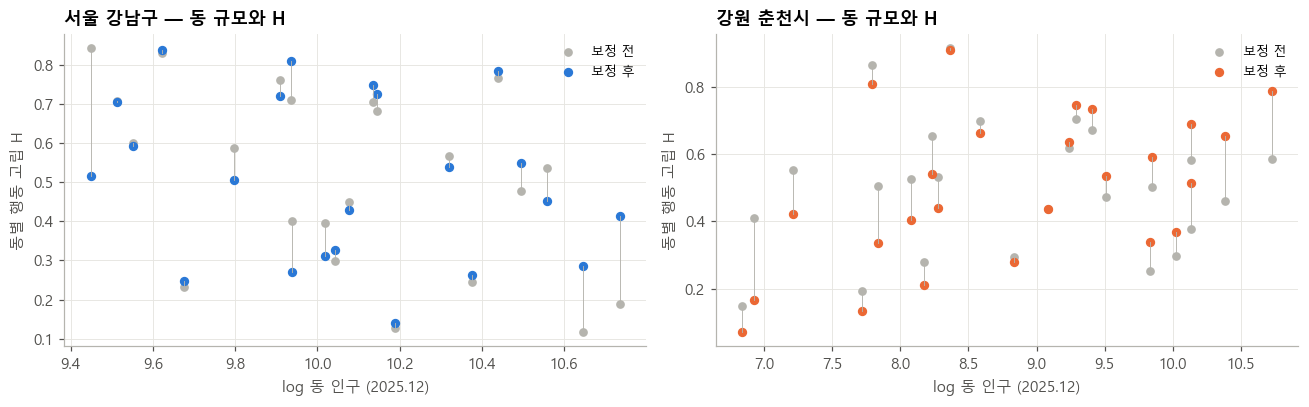

In [6]:
def dong(col, wcol='주민'):
    return U.groupby('SGIS코드')[[col, wcol]].apply(lambda g: np.average(g[col], weights=g[wcol].clip(lower=1)))
DG = pd.DataFrame({'H 보정 전': dong('H(보정 전)'), 'H 보정 후': dong('H')}).join(CODES.set_index('SGIS코드')[['지역', '읍면동명']])
DG['log 동 인구'] = np.log(POP['20251231']['계_총인구수']); DG['log 주간/야간'] = np.log(DAYNIGHT)
rows = []
for reg in MAIN:
    d = DG[DG['지역'] == reg]
    for c in ['log 동 인구', 'log 주간/야간']:
        rows.append({'지역': reg, '비교 대상': c, '보정 전 ρ': spearmanr(d['H 보정 전'], d[c])[0], '보정 후 ρ': spearmanr(d['H 보정 후'], d[c])[0]})
display(pd.DataFrame(rows).set_index(['지역', '비교 대상']).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, reg in zip(axes, MAIN):
    d = DG[DG['지역'] == reg]
    ax.scatter(d['log 동 인구'], d['H 보정 전'], color=GRAY, s=22, label='보정 전')
    ax.scatter(d['log 동 인구'], d['H 보정 후'], color=C_[reg], s=26, label='보정 후')
    for _, r in d.iterrows(): ax.plot([r['log 동 인구']] * 2, [r['H 보정 전'], r['H 보정 후']], color=GRAY, lw=.6)
    ax.set_xlabel('log 동 인구 (2025.12)'); ax.set_ylabel('동별 행동 고립 H'); ax.set_title(f'{reg} — 동 규모와 H'); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

## 3. 사회경제 취약 축 V — 혼자 사는 비율 + 공공부조 수급

> **왜** 부록 B에서 행동 지수는 경제·돌봄 취약을 놓쳤습니다(P3). 이를 별도 축으로 세웁니다.  
> **결과** 혼자 사는 비율(성·연령별)과 공공부조 수급(강남 기초생활수급자, 춘천 기초연금)으로 취약 축 V를 만들었습니다. 장애인 비율은 검증용으로 남겼습니다.


| 구성 지표 | 단위 | 강남 | 춘천 | 근거 |
|---|---|---|---|---|
| **혼자 사는 비율** = 1인세대 ÷ 인구 | 동 × 성 × 연령 | 주민등록 2024.12 | 주민등록 2024.12 | 1인 가구는 고립·고독사의 가장 일관된 위험 요인 (고독사 실태조사, 경남 판단도구) |
| **공공부조 수급** | 동 (강남은 동 × 성) | 기초생활수급자 ÷ 인구 | 65세+ 기초연금 수급률 | 경제적 취약 → 사회 참여 감소 (부록 B에서 행동 축이 놓친 부분) |

- 춘천은 동별 기초생활수급자가 공개돼 있지 않아(정보공개청구 결과 대기) 기초연금 수급률로 대신합니다. 결과가 오면 교체합니다.
- **검증용으로 남긴 지표**: 춘천 장애인 등록 비율은 V 구성에 넣지 않았습니다(순환 방지, 과제 P13).

In [7]:
U['혼자 사는 비율'] = U['1인세대_2024'] / U['주민_2024'].clip(lower=1)
gn_rate = pd.concat({s: w[s] / POP['20241231'][('남' if s == '남성' else '여') + '_총인구수'].reindex(w.index) for s in SEX}, names=['성별', 'SGIS코드'])
U['공공부조 수급'] = np.where(U['지역'] == '서울 강남구',
                          U.set_index(['성별', 'SGIS코드']).index.map(gn_rate * 100),
                          U['SGIS코드'].map(CH['기초연금 수급률(%)']))
U['V'] = (pct(U['혼자 사는 비율']) + pct(U['공공부조 수급'])) / 2
U['R_V'] = np.exp(SLOPE * (U['V'] - .5))
DG['V'] = dong('V', '주민_2024')
print('혼자 사는 비율(%) — 지역 × 연령 (거주 인구 가중)')
display((U.groupby(['지역', '연령5']).apply(lambda g: g['1인세대_2024'].sum() / g['주민_2024'].sum() * 100).unstack().round(1)))

혼자 사는 비율(%) — 지역 × 연령 (거주 인구 가중)


연령5,20대,30대,40대,50대,60대+
지역,,,,,
강원 춘천시,32.400,24.800,15.100,18.800,27.700
서울 강남구,25.600,35.500,17.000,13.000,18.500


## 4. 2축 결합 — 점수 · 유형 · 5단계 (규칙)

> **왜** 두 축을 하나의 점수로 합치면서도, 어떤 종류의 위험인지 알아야 연계할 서비스를 고를 수 있습니다.  
> **결과** 점수 = B × H배수 × V배수 × C, 유형 4가지(이중 위험·행동형·취약형·저위험), 5단계 3종(지역·생애단계·성별 안)을 규칙으로 정했습니다.


- **점수** = B × exp(0.6 × (H − 0.5)) × exp(0.6 × (V − 0.5)) × C — 각 축의 배수는 약 0.74~1.35배
- **유형**: 지역 안에서 거주 인구 가중 상위 1/3(공식 고립률 33%에 맞춤)을 '높음'으로 보고 이중 위험 / 행동형(H만 높음) / 취약형(V만 높음) / 저위험
- **5단계**: 지역 안 · 생애단계 안 · 성별 안 (누적 인구 5/15/33/60/100%, 부록 A와 같음)
- **주요 요인**: 같은 지역 · 성 · 연령 안 상위 20%인 구성 지표 → 에이전트의 '원인 분석' 문장

In [8]:
CUTS = [tuple(x) for x in FROZEN['5단계 기준(누적 인구 비중)']]; ORDER = [c for c, _ in CUTS]
def top_third(df, col, wcol='주민'):
    d = df.sort_values(col, ascending=False); cum = d[wcol].cumsum() / d[wcol].sum()
    return (cum <= 1 / 3).reindex(df.index)
def levels(df, score='우선순위 점수', wcol='주민'):
    d = df.sort_values(score, ascending=False); cum = d[wcol].cumsum() / d[wcol].sum()
    lab = pd.Series('정상', index=d.index)
    for name, cut in reversed(CUTS): lab[cum <= cut] = name
    return lab.reindex(df.index)
def build(Hcol, win='겨울 체류 유지'):
    U['적용 H'] = U[Hcol]; U['R_H'] = np.exp(SLOPE * (U[Hcol] - .5))
    U['우선순위 점수'] = U['B 기본 고립률(%)'] * U['R_H'] * U['R_V'] * U['C']
    hiH = pd.concat([top_third(g, Hcol) for _, g in U.groupby('지역')]).reindex(U.index)   # 행 순서를 U에 맞춤
    hiV = pd.concat([top_third(g, 'V') for _, g in U.groupby('지역')]).reindex(U.index)
    U['위험 유형'] = np.select([(hiH & hiV).values, hiH.values, hiV.values], ['이중 위험', '행동형', '취약형'], '저위험')
    U['단계'] = pd.concat([levels(g) for _, g in U.groupby('지역')])
    U['생애단계 내 단계'] = pd.concat([levels(g) for _, g in U.groupby(['지역', '연령5'])])
    U['성별 내 단계'] = pd.concat([levels(g) for _, g in U.groupby(['지역', '성별'])])
    lab = {'보정 체류도': '동네 체류 많음', win: '겨울에도 동네에 머묾', '혼자 사는 비율': '혼자 사는 비율 높음', '공공부조 수급': '공공부조 수급 많음'}
    P = pd.DataFrame({v: pct(U[k]) for k, v in lab.items()})
    U['주요 요인'] = P.apply(lambda r: ', '.join(r[r >= .8].sort_values(ascending=False).index) or '—', axis=1)
    U.loc[U['C'] > 1.03, '주요 요인'] += ' (+ 집단 소비 위축)'
    tp = U.groupby(['지역', '위험 유형'])['주민'].sum().unstack().reindex(columns=list(TYPE_C)).fillna(0)
    return (tp.div(tp.sum(axis=1), axis=0) * 100).round(1)
print('사전 등록 버전 — 유형별 거주 인구 비중(%)'); display(build('H'))

사전 등록 버전 — 유형별 거주 인구 비중(%)


위험 유형,이중 위험,행동형,취약형,저위험
지역,,,,
강원 춘천시,11.400,20.900,21.200,46.500
서울 강남구,16.800,16.500,16.500,50.300


## 5. 사전 등록 검증 — 실행 전에 고정한 기준으로 판정

> **왜** 결과를 본 뒤 기준을 고르면 검증이 무의미해지므로, 기준을 먼저 파일로 고정했습니다(P10).  
> **결과** 19개 중 18개 통과. 확증 가설 3개(강남 1인 세대 0.66, 춘천 이동률 0.71, 춘천 장애인 0.51)는 순열 검정·Holm 보정 후에도 통과했습니다. 춘천 동 규모 기준(D1, 0.49)만 실패했습니다.


기준은 `outputs/검증프로토콜_사전등록.json`에 실행 전에 적어 두었고, 결과를 본 뒤 바꾸지 않았습니다. p값은 **순열 검정**(동의 값을 10,000번 무작위로 섞어 우연히 그만한 상관이 나올 확률)으로 계산하고, 확증 가설 3개는 **Holm 보정**으로 다중 비교를 막습니다.

In [9]:
def perm(x, y, n=10000, seed=0):
    rx, ry = rankdata(x), rankdata(y); rx = (rx - rx.mean()) / rx.std(); ry = (ry - ry.mean()) / ry.std()
    r = (rx * ry).mean(); rng = np.random.default_rng(seed)
    null = np.array([(rx * rng.permutation(ry)).mean() for _ in range(n)])
    return r, (np.sum(null >= r) + 1) / (n + 1)
DG['혼자 사는 주민 비율(%)'] = ONE['20251231']['계_총세대수'] / POP['20251231']['계_총인구수'] * 100
DG = DG.join(CH[['인구 이동률(%)', '장애인 비율(%)', '기초연금 수급률(%)']])
gn, ch = DG[DG['지역'] == MAIN[0]], DG[DG['지역'] == MAIN[1]]
conf = [('H1a', '강남', '행동 H ↔ 혼자 사는 주민 비율', gn['H 보정 후'], gn['혼자 사는 주민 비율(%)']),
        ('H1b', '춘천', '행동 H ↔ 인구 이동률', ch['H 보정 후'], ch['인구 이동률(%)']),
        ('H2', '춘천', '취약 V ↔ 장애인 비율 (구성에 안 쓴 지표)', ch['V'], ch['장애인 비율(%)'])]
R = pd.DataFrame([{'가설': h, '지역': g, '내용': t, 'n': len(x), 'ρ': perm(x, y)[0], '순열 p (단측)': perm(x, y)[1]} for h, g, t, x, y in conf])
order = R['순열 p (단측)'].sort_values().index; m = len(R); ok = True
for i, ix in enumerate(order):                                          # Holm: 작은 p부터 α/(m−i)와 비교, 한 번 실패하면 이후 모두 기각 실패
    ok = ok and R.loc[ix, '순열 p (단측)'] <= .05 / (m - i); R.loc[ix, 'Holm 통과'] = '통과' if ok else '실패'
print('① 확증 가설'); display(R.round(3))
disc = []
for reg, d in [('강남', gn), ('춘천', ch)]:
    r1 = spearmanr(d['H 보정 후'], d['log 동 인구'])[0]; r2 = spearmanr(d['H 보정 후'], d['V'])[0]
    disc += [{'기준': 'D1', '지역': reg, '내용': '|ρ(H, log 동 인구)| < 0.3', 'ρ': r1, '판정': '통과' if abs(r1) < .3 else '실패'},
             {'기준': 'D2', '지역': reg, '내용': 'ρ(H, V) < 0.7 (두 축이 다른 것을 잼)', 'ρ': r2, '판정': '통과' if r2 < .7 else '실패'}]
D_ = pd.DataFrame(disc); print('② 판별 기준'); display(D_.round(3))

① 확증 가설


,가설,지역,내용,n,ρ,순열 p (단측),Holm 통과
0,H1a,강남,행동 H ↔ 혼자 사는 주민 비율,22,0.662,0.001,통과
1,H1b,춘천,행동 H ↔ 인구 이동률,25,0.714,0.000,통과
2,H2,춘천,취약 V ↔ 장애인 비율 (구성에 안 쓴 지표),25,0.505,0.007,통과


② 판별 기준


,기준,지역,내용,ρ,판정
0,D1,강남,"|ρ(H, log 동 인구)| < 0.3",-0.235,통과
1,D2,강남,"ρ(H, V) < 0.7 (두 축이 다른 것을 잼)",0.479,통과
2,D1,춘천,"|ρ(H, log 동 인구)| < 0.3",0.488,실패
3,D2,춘천,"ρ(H, V) < 0.7 (두 축이 다른 것을 잼)",-0.114,통과


In [10]:
%%time
# --- 신뢰도 R1: 반기 분할 안정성 (보정 체류도를 7~9월, 10~12월로 따로 계산)
h1 = stay(MON[['202507', '202508', '202509']].mean(axis=1).reindex(pd.MultiIndex.from_frame(U[K3])).values, U['주민_2025'], POP['20251231']['계_총인구수'])[1]
h2 = stay(MON[['202510', '202511', '202512']].mean(axis=1).reindex(pd.MultiIndex.from_frame(U[K3])).values, U['주민_2025'], POP['20251231']['계_총인구수'])[1]
r1 = pd.DataFrame({'a': h1, 'b': h2, '지역': U['지역'], 'cell': U['cell']}).groupby(['지역', 'cell']).apply(lambda g: spearmanr(g['a'], g['b'])[0]).groupby('지역').mean()
# --- 신뢰도 R2: 주민등록 시점 교체 (행동 축 2024.12, 취약 축 2025.12)
_, adj24, _ = stay(U['집단유동'], U['주민_2024'], POP['20241231']['계_총인구수'])
H24 = (pct(adj24) + pct(U['겨울 체류 유지'])) / 2
alone25 = U['1인세대_2025'] / U['주민_2025'].clip(lower=1)
gn25 = pd.concat({s: w[s] / POP['20251231'][('남' if s == '남성' else '여') + '_총인구수'].reindex(w.index) for s in SEX}, names=['성별', 'SGIS코드'])
pub25 = np.where(U['지역'] == '서울 강남구', U.set_index(['성별', 'SGIS코드']).index.map(gn25 * 100), U['공공부조 수급'])
V25 = (pct(alone25) + pct(pd.Series(pub25, index=U.index))) / 2
def score(H=None, V=None, slope=SLOPE, a=1., b=1.):
    H = U['H'] if H is None else H; V = U['V'] if V is None else V
    return U['B 기본 고립률(%)'] * np.exp(a * slope * (H - .5)) * np.exp(b * slope * (V - .5)) * U['C']
def compare(alt, base='우선순위 점수', share=.15):
    out = {}
    for reg in MAIN:
        i = U['지역'] == reg; n = int(i.sum() * share)
        A, Bs = U.loc[i, base], alt[i]
        out[reg] = {'순위 ρ': spearmanr(A, Bs)[0], '상위 15% 겹침(%)': len(set(A.nlargest(n).index) & set(Bs.nlargest(n).index)) / n * 100}
    return pd.DataFrame(out).T
rel = []
for reg in MAIN:
    rel.append({'기준': 'R1', '지역': reg, '내용': '반기 분할 동 순위 ρ ≥ 0.7', '값': r1[reg], '판정': '통과' if r1[reg] >= .7 else '실패'})
c2 = compare(score(H24, V25))
for reg in MAIN:
    v = c2.loc[reg]; rel.append({'기준': 'R2', '지역': reg, '내용': '시점 교체: 순위 ρ ≥ 0.9 & 상위 15% 겹침 ≥ 70%', '값': f"ρ {v['순위 ρ']:.2f} / 겹침 {v['상위 15% 겹침(%)']:.0f}%",
                '판정': '통과' if v['순위 ρ'] >= .9 and v['상위 15% 겹침(%)'] >= 70 else '실패'})
for nm, kw in [('기울기 0.3', dict(slope=.3)), ('기울기 1.0', dict(slope=1.)), ('H:V = 2:1', dict(a=4 / 3, b=2 / 3)), ('H:V = 1:2', dict(a=2 / 3, b=4 / 3))]:
    c3 = compare(score(**kw))
    for reg in MAIN:
        v = c3.loc[reg, '상위 15% 겹침(%)']; rel.append({'기준': 'R3', '지역': reg, '내용': f'가중치 민감도 ({nm}): 겹침 ≥ 70%', '값': f'{v:.0f}%', '판정': '통과' if v >= 70 else '실패'})
REL = pd.DataFrame(rel); print('③ 신뢰도 기준'); display(REL.round(3))

③ 신뢰도 기준


,기준,지역,내용,값,판정
0,R1,서울 강남구,반기 분할 동 순위 ρ ≥ 0.7,0.996,통과
1,R1,강원 춘천시,반기 분할 동 순위 ρ ≥ 0.7,0.981,통과
2,R2,서울 강남구,시점 교체: 순위 ρ ≥ 0.9 & 상위 15% 겹침 ≥ 70%,ρ 1.00 / 겹침 94%,통과
3,R2,강원 춘천시,시점 교체: 순위 ρ ≥ 0.9 & 상위 15% 겹침 ≥ 70%,ρ 0.99 / 겹침 97%,통과
4,R3,서울 강남구,가중치 민감도 (기울기 0.3): 겹침 ≥ 70%,76%,통과
5,R3,강원 춘천시,가중치 민감도 (기울기 0.3): 겹침 ≥ 70%,84%,통과
6,R3,서울 강남구,가중치 민감도 (기울기 1.0): 겹침 ≥ 70%,88%,통과
7,R3,강원 춘천시,가중치 민감도 (기울기 1.0): 겹침 ≥ 70%,97%,통과
8,R3,서울 강남구,가중치 민감도 (H:V = 2:1): 겹침 ≥ 70%,82%,통과
9,R3,강원 춘천시,가중치 민감도 (H:V = 2:1): 겹침 ≥ 70%,86%,통과


CPU times: total: 188 ms
Wall time: 189 ms


In [11]:
ALL = pd.concat([R.rename(columns={'가설': '기준', 'Holm 통과': '판정'})[['기준', '지역', '내용', 'ρ', '판정']],
                 D_[['기준', '지역', '내용', 'ρ', '판정']], REL.rename(columns={'값': 'ρ'})[['기준', '지역', '내용', 'ρ', '판정']]])
print(f"사전 등록 기준 {len(ALL)}개 중 통과 {int((ALL['판정'] == '통과').sum())}개")
ALL.to_csv(OUTD / '검증결과_2축모델.csv', index=False, encoding='utf-8-sig')
ALL[ALL['판정'] != '통과']

사전 등록 기준 19개 중 통과 18개


,기준,지역,내용,ρ,판정
2,D1,춘천,"|ρ(H, log 동 인구)| < 0.3",0.488,실패


### 5-1. 사후 진단 — 실패한 기준의 원인과 수정안 (사전 등록 아님)

> **왜** 실패한 기준은 숨기지 않고 원인을 찾아야 합니다. 단, 사후 수정임을 분명히 표시합니다.  
> **결과** 원인은 '겨울 체류 유지'가 관광·상업지의 계절 방문객에 끌려간 것(춘천 상업성과 ρ −0.90)입니다. 겨울 지표에도 같은 보정을 걸자(H_v2) 동 규모 편향이 0.12로 줄고 독립 지표와의 관계(0.67·0.51)는 유지됐습니다.


⚠ 이 절은 결과를 본 뒤에 한 분석입니다. 위의 사전 등록 판정은 바꾸지 않고 그대로 보고합니다. 여기서 만든 수정안은 **새 자료로 다시 확인해야 하는 가설**로 다룹니다.

In [12]:
POP25 = POP['20251231']['계_총인구수']
U['보정 겨울 체류'], wcoef = adjust(U['겨울 체류 유지'], POP25)        # 수정안: 겨울 지표에도 같은 보정을 적용
U['H_v2'] = (pct(U['보정 체류도']) + pct(U['보정 겨울 체류'])) / 2
for c in ['보정 체류도', '겨울 체류 유지', '보정 겨울 체류']:
    U['_p ' + c] = pct(U[c])
comp = {'보정 체류도 (H 구성 ①)': '_p 보정 체류도', '겨울 체류 유지 (H 구성 ②)': '_p 겨울 체류 유지', 'H (사전 등록)': 'H',
        '보정 겨울 체류 (수정안 ②)': '_p 보정 겨울 체류', 'H_v2 (수정안)': 'H_v2'}
for nm, c in comp.items(): DG[nm] = dong(c)
rows = []
for reg, d in [('강남', DG[DG['지역'] == MAIN[0]]), ('춘천', DG[DG['지역'] == MAIN[1]])]:
    for nm in comp:
        rows.append({'지역': reg, '지표 (동 평균)': nm, 'ρ(log 동 인구)': spearmanr(d[nm], d['log 동 인구'])[0], 'ρ(log 주간/야간)': spearmanr(d[nm], d['log 주간/야간'])[0]})
print('① 어느 구성 지표가 동 규모와 엮였나'); display(pd.DataFrame(rows).set_index(['지역', '지표 (동 평균)']).round(2))
print('겨울 지표 보정 계수:'); display(wcoef.round(3))
def partial(x, y, z):                                                  # 순위 편상관: z(동 규모)의 영향을 뺀 x·y 관계
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz); ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return np.corrcoef(ex, ey)[0, 1]
gn, ch = DG[DG['지역'] == MAIN[0]], DG[DG['지역'] == MAIN[1]]
print(f"② 춘천: 인구 이동률 ↔ log 동 인구 ρ = {spearmanr(ch['인구 이동률(%)'], ch['log 동 인구'])[0]:.2f}")
print(f"   동 규모를 뺀 편상관 — H(사전 등록) ↔ 이동률 {partial(ch['H 보정 후'], ch['인구 이동률(%)'], ch['log 동 인구']):.2f}, "
      f"H_v2 ↔ 이동률 {partial(ch['H_v2 (수정안)'], ch['인구 이동률(%)'], ch['log 동 인구']):.2f}")
v2 = []
for h, reg, t, x, y in [('H1a', '강남', 'H_v2 ↔ 혼자 사는 주민 비율', gn['H_v2 (수정안)'], gn['혼자 사는 주민 비율(%)']),
                        ('H1b', '춘천', 'H_v2 ↔ 인구 이동률', ch['H_v2 (수정안)'], ch['인구 이동률(%)'])]:
    r, p_ = perm(x, y); v2.append({'기준': h, '지역': reg, '내용': t, 'ρ': r, 'p': p_, '판정': '통과' if p_ <= .05 / 2 else '실패'})
for reg, d in [('강남', gn), ('춘천', ch)]:
    r1 = spearmanr(d['H_v2 (수정안)'], d['log 동 인구'])[0]; r2 = spearmanr(d['H_v2 (수정안)'], d['V'])[0]
    v2 += [{'기준': 'D1', '지역': reg, '내용': '|ρ(H_v2, log 동 인구)| < 0.3', 'ρ': r1, '판정': '통과' if abs(r1) < .3 else '실패'},
           {'기준': 'D2', '지역': reg, '내용': 'ρ(H_v2, V) < 0.7', 'ρ': r2, '판정': '통과' if r2 < .7 else '실패'}]
V2 = pd.DataFrame(v2); print('③ 수정안(H_v2)을 같은 기준으로 확인 (H1은 Holm과 같은 수준인 p ≤ 0.025로 판정)'); display(V2.round(3))
FINAL = 'H_v2' if (V2['판정'] == '통과').all() else 'H'
print('→ 적용 모델:', '수정안 H_v2 (사후 수정, 다음 자료로 재확인 필요)' if FINAL == 'H_v2' else '사전 등록 H')

① 어느 구성 지표가 동 규모와 엮였나


ρ(log 동 인구)  ρ(log 주간/야간)
지역 지표 (동 평균)                                   
강남 보정 체류도 (H 구성 ①)          0.050         0.050
   겨울 체류 유지 (H 구성 ②)       -0.530         0.080
   H (사전 등록)               -0.240         0.100
   보정 겨울 체류 (수정안 ②)         0.040         0.030
   H_v2 (수정안)               0.020         0.050
춘천 보정 체류도 (H 구성 ①)          0.330        -0.280
   겨울 체류 유지 (H 구성 ②)        0.490        -0.900
   H (사전 등록)                0.490        -0.740
   보정 겨울 체류 (수정안 ②)        -0.230         0.100
   H_v2 (수정안)               0.120        -0.180

겨울 지표 보정 계수:


,상업성 계수,규모 계수
강원 춘천시,-0.405,0.046
서울 강남구,0.021,-0.032


② 춘천: 인구 이동률 ↔ log 동 인구 ρ = 0.40
   동 규모를 뺀 편상관 — H(사전 등록) ↔ 이동률 0.65, H_v2 ↔ 이동률 0.50


③ 수정안(H_v2)을 같은 기준으로 확인 (H1은 Holm과 같은 수준인 p ≤ 0.025로 판정)


,기준,지역,내용,ρ,p,판정
0,H1a,강남,H_v2 ↔ 혼자 사는 주민 비율,0.665,0.001,통과
1,H1b,춘천,H_v2 ↔ 인구 이동률,0.505,0.005,통과
2,D1,강남,"|ρ(H_v2, log 동 인구)| < 0.3",0.024,NaN,통과
3,D2,강남,"ρ(H_v2, V) < 0.7",0.451,NaN,통과
4,D1,춘천,"|ρ(H_v2, log 동 인구)| < 0.3",0.118,NaN,통과
5,D2,춘천,"ρ(H_v2, V) < 0.7",-0.026,NaN,통과


→ 적용 모델: 수정안 H_v2 (사후 수정, 다음 자료로 재확인 필요)


## 6. 최종 결과 — 유형 · 단계 · 우선 지원 대상

> **왜** 최종 버전으로 우선 지원 대상과 유형을 확정해 05·06에 넘깁니다.  
> **결과** 유형 구성은 두 지역 모두 이중 위험 14~16%입니다. 20대의 이중 위험 비중이 23~24%로 높고, 60대+는 취약형이 많습니다. 가중치·시점을 바꿔도 상위 15%의 79~100%가 유지됩니다.


In [13]:
TP = build(FINAL, win='보정 겨울 체류' if FINAL == 'H_v2' else '겨울 체류 유지')
DG['H 최종'] = dong(FINAL)
print('유형별 거주 인구 비중(%)'); display(TP)
# 최종 버전의 가중치·시점 민감도 (R2·R3와 같은 방식)
_, adj24, _ = stay(U['집단유동'], U['주민_2024'], POP['20241231']['계_총인구수'])
w24 = adjust(U['겨울 체류 유지'], POP['20241231']['계_총인구수'])[0] if FINAL == 'H_v2' else U['겨울 체류 유지']
sens = {'시점 교체 (2024.12 ↔ 2025.12)': compare(score(H=(pct(adj24) + pct(w24)) / 2, V=V25))}
for nm, kw in [('기울기 0.3', dict(slope=.3)), ('기울기 1.0', dict(slope=1.)), ('H:V = 2:1', dict(a=4 / 3, b=2 / 3)), ('H:V = 1:2', dict(a=2 / 3, b=4 / 3))]:
    sens[nm] = compare(score(H=U[FINAL], **kw))
print('최종 버전 민감도 — 상위 15% 겹침(%)'); display(pd.DataFrame({k: v['상위 15% 겹침(%)'] for k, v in sens.items()}).round(0))

유형별 거주 인구 비중(%)


위험 유형,이중 위험,행동형,취약형,저위험
지역,,,,
강원 춘천시,13.900,19.400,18.700,48.000
서울 강남구,16.300,16.600,17.000,50.200


최종 버전 민감도 — 상위 15% 겹침(%)


,시점 교체 (2024.12 ↔ 2025.12),기울기 0.3,기울기 1.0,H:V = 2:1,H:V = 1:2
서울 강남구,97.000,79.000,85.000,85.000,91.000
강원 춘천시,100.000,92.000,84.000,95.000,81.000


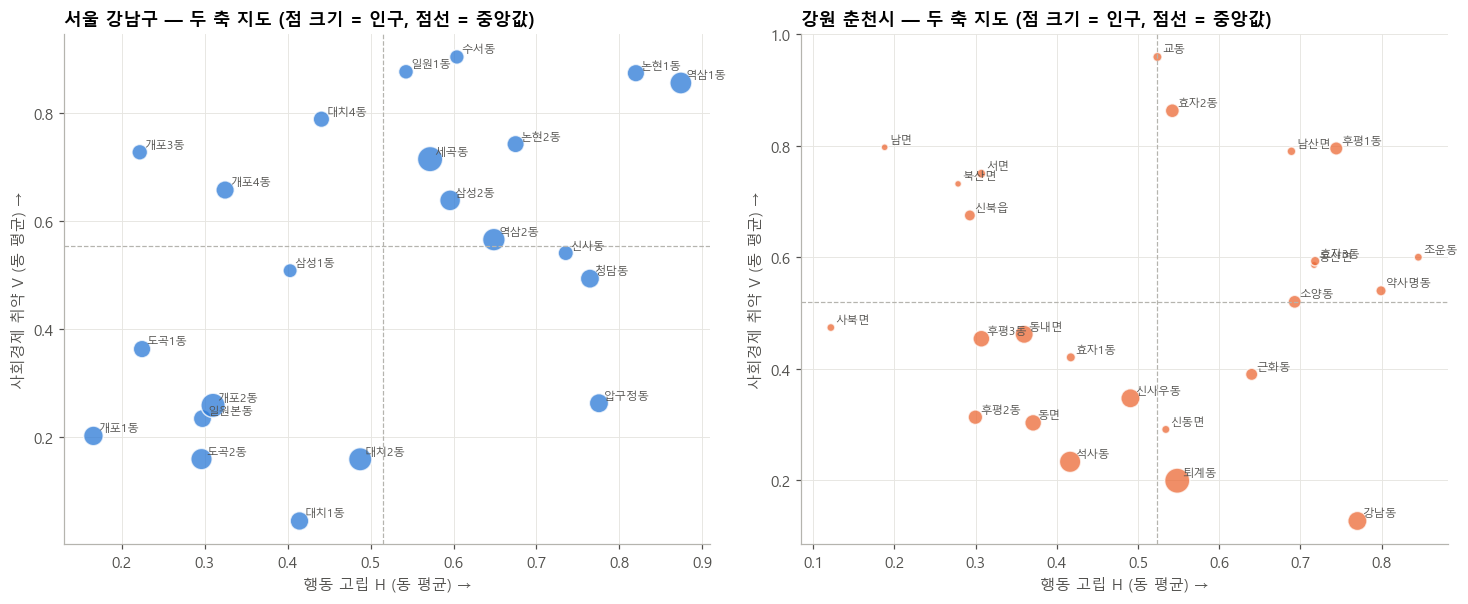

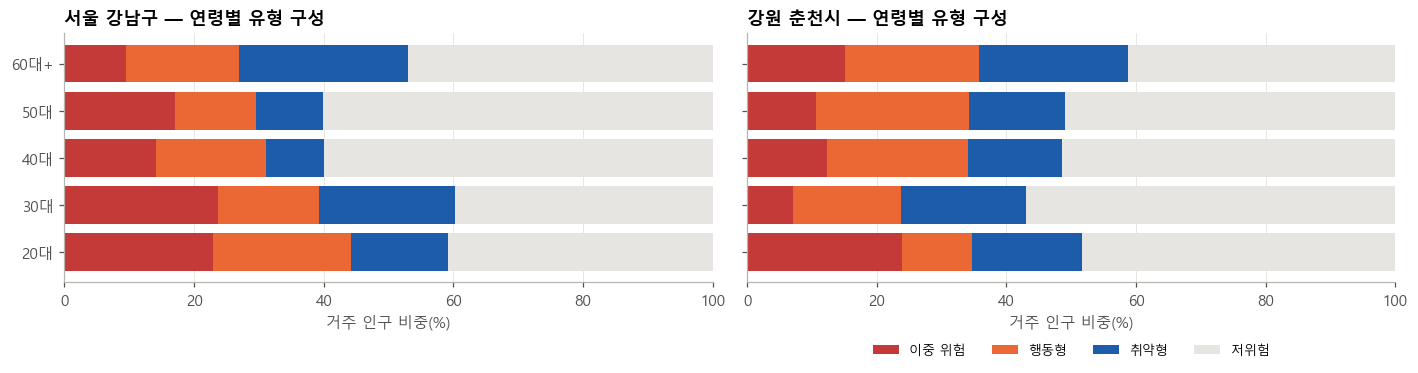

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))
for ax, reg in zip(axes, MAIN):
    d = DG[DG['지역'] == reg]; ax.axvline(d['H 최종'].median(), color=GRAY, lw=.8, ls='--'); ax.axhline(d['V'].median(), color=GRAY, lw=.8, ls='--')
    sz = POP25.loc[d.index] / POP25.max() * 260 + 15
    ax.scatter(d['H 최종'], d['V'], s=sz, color=C_[reg], alpha=.75, edgecolor='white')
    for i, r in d.iterrows(): ax.annotate(r['읍면동명'].replace('(구 일원2동)', ''), (r['H 최종'], r['V']), fontsize=7.5, xytext=(3, 3), textcoords='offset points', color=INK2)
    ax.set_xlabel('행동 고립 H (동 평균) →'); ax.set_ylabel('사회경제 취약 V (동 평균) →'); ax.set_title(f'{reg} — 두 축 지도 (점 크기 = 인구, 점선 = 중앙값)')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, reg in zip(axes, MAIN):
    t = U[U['지역'] == reg].groupby(['연령5', '위험 유형'])['주민'].sum().unstack().reindex(columns=list(TYPE_C)).fillna(0).reindex(AGE5)
    t = t.div(t.sum(axis=1), axis=0) * 100; left = np.zeros(len(t))
    for c in TYPE_C:
        ax.barh(t.index, t[c], left=left, color=TYPE_C[c], label=c); left += t[c].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('거주 인구 비중(%)'); ax.set_title(f'{reg} — 연령별 유형 구성')
axes[1].legend(ncol=4, fontsize=8.5, loc='upper center', bbox_to_anchor=(.5, -.2)); plt.tight_layout(); plt.show()

In [15]:
cols = ['읍면동명', '성별', '연령5', '주민', '위험 유형', '단계', '생애단계 내 단계', 'B 기본 고립률(%)', 'R_H', 'R_V', 'C', '우선순위 점수', '주요 요인']
for r in MAIN:
    print(f'[{r}] 우선 지원 대상 상위 8'); display(U[U['지역'] == r].nlargest(8, '우선순위 점수')[cols].round(2))
print('지역 × 생애단계별 1순위'); display(U.sort_values('우선순위 점수', ascending=False).groupby(['지역', '연령5'], sort=False).head(1).sort_values(['지역', '연령5'])[['지역'] + cols].round(2))
lv = U.groupby(['지역', '연령5', '단계'])['주민'].sum().unstack().reindex(columns=ORDER).fillna(0)
print('지역 내 단계 — 연령별 거주 인구 분포(%)'); display((lv.div(lv.sum(axis=1), axis=0) * 100).round(1))
ty = U.groupby(['지역', '연령5', '위험 유형'])['주민'].sum().unstack().reindex(columns=list(TYPE_C)).fillna(0)
print('연령별 유형 구성(%)'); display((ty.div(ty.sum(axis=1), axis=0) * 100).round(1))

[서울 강남구] 우선 지원 대상 상위 8


,읍면동명,성별,연령5,주민,위험 유형,단계,생애단계 내 단계,B 기본 고립률(%),R_H,R_V,C,우선순위 점수,주요 요인
74,역삼1동,남성,60대+,2734,이중 위험,심각,심각,42.620,1.350,1.240,1.010,72.460,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음"
13,논현1동,남성,50대,1399,이중 위험,심각,심각,40.240,1.330,1.260,1.070,72.080,"겨울에도 동네에 머묾, 동네 체류 많음, 혼자 사는 비율 높음, 공공부조 수급 많음..."
73,역삼1동,남성,50대,2395,이중 위험,심각,심각,40.240,1.330,1.260,1.070,72.080,"동네 체류 많음, 혼자 사는 비율 높음, 겨울에도 동네에 머묾 (+ 집단 소비 위축)"
14,논현1동,남성,60대+,1947,이중 위험,심각,심각,42.620,1.300,1.240,1.010,69.550,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음, 공공부조 수급 많음"
163,수서동,남성,50대,776,이중 위험,심각,경계,40.240,1.240,1.300,1.070,69.190,"공공부조 수급 많음, 동네 체류 많음, 혼자 사는 비율 높음, 겨울에도 동네에 머묾..."
164,수서동,남성,60대+,2693,취약형,심각,경계,42.620,1.030,1.350,1.010,59.860,"혼자 사는 비율 높음, 공공부조 수급 많음"
79,역삼1동,여성,60대+,2979,이중 위험,심각,경계,36.420,1.330,1.180,1.030,59.030,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음 (+ 집단 소비 위축)"
84,역삼2동,남성,60대+,2536,행동형,심각,경계,42.620,1.240,1.060,1.010,56.690,겨울에도 동네에 머묾


[강원 춘천시] 우선 지원 대상 상위 8


,읍면동명,성별,연령5,주민,위험 유형,단계,생애단계 내 단계,B 기본 고립률(%),R_H,R_V,C,우선순위 점수,주요 요인
243,동산면,남성,50대,110,이중 위험,심각,심각,40.240,1.270,1.130,0.940,54.400,"동네 체류 많음, 겨울에도 동네에 머묾"
379,후평1동,여성,60대+,2217,이중 위험,심각,심각,36.420,1.200,1.200,1.040,54.270,"겨울에도 동네에 머묾, 공공부조 수급 많음 (+ 집단 소비 위축)"
283,남산면,남성,50대,276,이중 위험,심각,심각,40.240,1.200,1.180,0.940,53.750,"겨울에도 동네에 머묾, 공공부조 수급 많음"
349,약사명동,여성,60대+,841,이중 위험,심각,심각,36.420,1.300,1.070,1.040,52.980,"겨울에도 동네에 머묾, 동네 체류 많음 (+ 집단 소비 위축)"
344,약사명동,남성,60대+,623,이중 위험,심각,심각,42.620,1.300,1.040,0.920,52.880,"겨울에도 동네에 머묾, 동네 체류 많음"
334,조운동,남성,60대+,443,이중 위험,심각,심각,42.620,1.260,1.060,0.920,52.250,"겨울에도 동네에 머묾, 혼자 사는 비율 높음, 동네 체류 많음"
374,후평1동,남성,60대+,1800,이중 위험,심각,경계,42.620,1.140,1.150,0.920,51.630,"공공부조 수급 많음, 겨울에도 동네에 머묾"
323,교동,남성,50대,276,취약형,심각,심각,40.240,1.020,1.300,0.940,50.620,"공공부조 수급 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음"


지역 × 생애단계별 1순위


,지역,읍면동명,성별,연령5,주민,위험 유형,단계,생애단계 내 단계,B 기본 고립률(%),R_H,R_V,C,우선순위 점수,주요 요인
370,강원 춘천시,후평1동,남성,20대,863,이중 위험,주의,심각,26.400,1.170,1.240,0.980,37.600,"겨울에도 동네에 머묾, 공공부조 수급 많음, 혼자 사는 비율 높음"
281,강원 춘천시,남산면,남성,30대,105,이중 위험,경계,심각,28.670,1.330,1.200,0.930,42.560,"겨울에도 동네에 머묾, 동네 체류 많음, 공공부조 수급 많음"
282,강원 춘천시,남산면,남성,40대,166,이중 위험,경계,심각,31.910,1.270,1.210,0.940,46.130,"겨울에도 동네에 머묾, 공공부조 수급 많음, 동네 체류 많음, 혼자 사는 비율 높음"
243,강원 춘천시,동산면,남성,50대,110,이중 위험,심각,심각,40.240,1.270,1.130,0.940,54.400,"동네 체류 많음, 겨울에도 동네에 머묾"
379,강원 춘천시,후평1동,여성,60대+,2217,이중 위험,심각,심각,36.420,1.200,1.200,1.040,54.270,"겨울에도 동네에 머묾, 공공부조 수급 많음 (+ 집단 소비 위축)"
10,서울 강남구,논현1동,남성,20대,1450,이중 위험,경계,심각,26.400,1.240,1.260,1.100,45.690,"혼자 사는 비율 높음, 겨울에도 동네에 머묾, 동네 체류 많음, 공공부조 수급 많음..."
71,서울 강남구,역삼1동,남성,30대,4955,이중 위험,주의,경계,28.670,1.150,1.260,1.060,43.860,"혼자 사는 비율 높음, 동네 체류 많음 (+ 집단 소비 위축)"
72,서울 강남구,역삼1동,남성,40대,3149,이중 위험,심각,심각,31.910,1.350,1.260,1.040,56.470,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음 (+ 집단 소비 위축)"
13,서울 강남구,논현1동,남성,50대,1399,이중 위험,심각,심각,40.240,1.330,1.260,1.070,72.080,"겨울에도 동네에 머묾, 동네 체류 많음, 혼자 사는 비율 높음, 공공부조 수급 많음..."
74,서울 강남구,역삼1동,남성,60대+,2734,이중 위험,심각,심각,42.620,1.350,1.240,1.010,72.460,"동네 체류 많음, 겨울에도 동네에 머묾, 혼자 사는 비율 높음"


지역 내 단계 — 연령별 거주 인구 분포(%)


단계              심각     경계     주의     관심     정상
지역     연령5                                    
강원 춘천시 20대   0.000  0.000 10.800  8.000 81.200
       30대   0.000  0.500  2.800  9.600 87.100
       40대   0.000  3.800  5.200  8.500 82.500
       50대   6.900 10.000 19.300 47.800 16.000
       60대+ 10.000 20.700 26.100 43.200  0.000
서울 강남구 20대   0.000  2.300 10.200 21.500 66.000
       30대   0.000  0.000 12.000 31.700 56.300
       40대   3.100  3.400 16.900 24.800 51.800
       50대   6.900 15.000 20.600 30.300 27.300
       60대+ 10.100 20.200 27.100 25.000 17.700

연령별 유형 구성(%)


위험 유형        이중 위험    행동형    취약형    저위험
지역     연령5                             
강원 춘천시 20대  23.900 10.900 16.900 48.300
       30대   7.100 16.700 19.300 56.900
       40대  12.400 21.600 14.600 51.400
       50대  10.600 23.600 14.900 50.900
       60대+ 15.100 20.600 23.100 41.200
서울 강남구 20대  22.900 21.200 15.100 40.800
       30대  23.600 15.600 21.100 39.700
       40대  14.100 17.000  9.100 59.900
       50대  17.100 12.500 10.300 60.100
       60대+  9.400 17.400 26.100 47.000

## 7. 참고 비교 — SKT 지표 · 보정 전 · 학습형 (확증 아님)

> **왜** 정답(SKT)과 이전 모델에 비해 무엇이 달라졌는지 참고로 확인합니다.  
> **결과** SKT 지표와는 0.40(보정 전 0.51)으로 조금 멀어졌습니다. 주민등록 혼자 사는 비율은 SKT 1인가구 추정과 0.89로 맞습니다. 학습형과 상위 15% 겹침은 강남 55%, 춘천 81%입니다.


In [16]:
L = []
for mth in range(7, 13):
    d = pd.read_excel(EXT / f'seoul_interest/interest_2025_{mth:02d}.xlsx'); L.append(d.loc[:, ~d.columns.astype(str).str.startswith('Unnamed')])
si = pd.concat(L); GI = '외출-커뮤니케이션이 모두 적은 집단(전체)'
si['연령5'] = si['연령대'].map(a5); si['성별'] = si['성별'].map({1: '남성', 2: '여성'})
T = si.dropna(subset=['연령5']).groupby(['행정동코드', '자치구', '성별', '연령5'])[['총인구', '1인가구수', GI]].sum().reset_index()
T['y'] = T[GI] / T['총인구']; T['y_rel'] = T['y'] / T.groupby(['성별', '연령5'])['y'].transform('mean'); T['skt_alone'] = T['1인가구수'] / T['총인구']
T = T[T['자치구'] == '강남구'].assign(SGIS코드=lambda d: d['행정동코드'].astype(str) + '0'); T = T[T['SGIS코드'] != '11230740']   # 1인가구 기반 집단이 0인 결함 동 제외
E = U[U['지역'] == '서울 강남구'].merge(T[['SGIS코드', '성별', '연령5', 'y_rel', 'skt_alone']], on=K3)
wr = lambda a, b: np.mean([spearmanr(g[a], g[b])[0] for _, g in E.groupby('cell')])
ref = pd.Series({'H 사전 등록 ↔ SKT 고립지표': wr('H', 'y_rel'), 'H_v2 수정안 ↔ SKT 고립지표': wr('H_v2', 'y_rel'), 'H 보정 전 ↔ SKT 고립지표': wr('H(보정 전)', 'y_rel'),
                 'V ↔ SKT 고립지표': wr('V', 'y_rel'), '최종 점수 ↔ SKT 고립지표': wr('우선순위 점수', 'y_rel'),
                 '주민등록 혼자 사는 비율 ↔ SKT 1인가구 추정': wr('혼자 사는 비율', 'skt_alone')}).rename('강남, 같은 성·연령 안 동 순위 ρ 평균')
display(ref.round(3).to_frame())
OLD = pd.read_csv(OUTD / '위험도_강남_춘천_동x성x연령.csv', dtype={'SGIS코드': str})
U = U.merge(OLD[K3 + ['위험점수']].rename(columns={'위험점수': '학습형 점수'}), on=K3, how='left')
print('학습형(부록 A)과의 비교'); display(compare(U['학습형 점수']).round(2))

,"강남, 같은 성·연령 안 동 순위 ρ 평균"
H 사전 등록 ↔ SKT 고립지표,0.426
H_v2 수정안 ↔ SKT 고립지표,0.397
H 보정 전 ↔ SKT 고립지표,0.506
V ↔ SKT 고립지표,0.185
최종 점수 ↔ SKT 고립지표,0.329
주민등록 혼자 사는 비율 ↔ SKT 1인가구 추정,0.892


학습형(부록 A)과의 비교


,순위 ρ,상위 15% 겹침(%)
서울 강남구,0.760,54.550
강원 춘천시,0.850,81.080


## 8. 결과 저장 — 05 복지자원 매핑 · 06 에이전트로 넘길 것

> **왜** 05·06이 바로 쓸 수 있는 형태로 결과와 설정을 남깁니다.  
> **결과** outputs/위험도_2축_강남_춘천_동x성x연령.csv(470행), 모델설정_2축.json, 검증결과_2축모델.csv를 저장했습니다.


In [17]:
SAVE = ['지역', '읍면동명', 'SGIS코드', '행정기관코드', '유형', '성별', '연령5', '주민', 'B 기본 고립률(%)', '보정 체류도', '겨울 체류 유지', '보정 겨울 체류',
        'H', 'H_v2', '적용 H', 'R_H', '혼자 사는 비율', '공공부조 수급', 'V', 'R_V', 'C', '우선순위 점수', '위험 유형', '단계', '생애단계 내 단계', '성별 내 단계', '주요 요인']
U[SAVE].rename(columns={'유형': '읍면동 구분'}).to_csv(OUTD / '위험도_2축_강남_춘천_동x성x연령.csv', index=False, encoding='utf-8-sig')
cfg = {'작성': '2026-10-14', '모델': '2축 지수형 (정답 미사용)', '적용 행동 축': FINAL, '배수 기울기': SLOPE,
       '행동 축 H': ['보정 체류도', '보정 겨울 체류' if FINAL == 'H_v2' else '겨울 체류 유지'],
       '보정 변수': ['성·연령 더미', 'log 주간/야간 유동비(동)', 'log 동 인구'], '취약 축 V': ['혼자 사는 비율', '공공부조 수급(강남 기초생활수급자 / 춘천 기초연금)'],
       '주민등록 시점': {'행동 축': '2025.12', '취약 축': '2024.12'}, '유형 기준': '지역 안 거주 인구 가중 상위 1/3',
       'B·C·5단계·T': '모델설정_동결.json 그대로', '검증': '검증프로토콜_사전등록.json → 검증결과_2축모델.csv'}
json.dump(cfg, open(OUTD / '모델설정_2축.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('저장:', OUTD / '위험도_2축_강남_춘천_동x성x연령.csv', len(U), '행 | 적용 H:', FINAL)

저장: outputs\위험도_2축_강남_춘천_동x성x연령.csv 470 행 | 적용 H: H_v2


## 9. 요약

> **왜** 결과와 한계를 쉽게 정리합니다.  
> **결과** H_v2는 사후 수정이라 다음 자료로 재확인이 필요하다는 점을 한계에 적었습니다.


### 한 줄 요약
**SKT 정답을 쓰지 않은 2축 지수(행동 고립 × 사회경제 취약)는 실행 전에 고정한 기준 19개 중 18개를 통과했습니다.** 확증 가설 3개는 모두 통과했습니다. 실패한 1개(춘천의 동 규모 편향)는 원인을 찾아 고쳤고, 고친 버전은 '사후 수정'으로 표시해 적용했습니다.

### 무엇이 바뀌었나 (이전 주 모델 = 부록 A 학습형)
| 항목 | 이전 (학습형) | 지금 (2축 지수형) |
|---|---|---|
| 가중치 | 강남 SKT 정답으로 학습 | 이론으로 미리 정함 (정답 미사용) |
| 지역 | 강남에서 학습 → 춘천에 옮겨 적용 | 두 지역에 같은 규칙, 지역별로 따로 검증 |
| 위험의 종류 | 한 축 (행동 + 구조 섞임) | **두 축 분리**: 행동 고립 H, 사회경제 취약 V → 유형 4가지 |
| 주민등록 시점 | 2026.9 (분석 기간과 1년 차이) | 행동 축 2025.12, 취약 축 2024.12 |
| 동 규모 편향 (강남) | ρ −0.50 | **0.02** |
| 검증 | SKT 정답 하나 | 사전 등록한 독립 기준 19개 + 순열 검정·Holm 보정 |

### 검증 결과
| 기준 | 강남 | 춘천 | 판정 |
|---|---|---|---|
| H1 행동 축 ↔ 독립 행정 지표 | 혼자 사는 주민 비율 ρ 0.66 (p 0.001) | 인구 이동률 ρ 0.71 (p < 0.001) | 통과 |
| H2 취약 축 ↔ 구성에 안 쓴 지표 | — (해당 지표 없음) | 장애인 비율 ρ 0.51 (p 0.007) | 통과 |
| D1 동 규모와 무관 | −0.24 | **0.49** | 춘천 실패 → 5-1에서 수정 |
| D2 두 축이 서로 다름 | 0.48 | −0.11 | 통과 |
| R1 반기 분할 안정성 | 0.996 | 0.981 | 통과 |
| R2 주민등록 시점 교체 | 상위 15% 겹침 94% | 97% | 통과 |
| R3 가중치 바꾸기 (4가지) | 76~97% | 84~97% | 통과 |

### 실패한 기준에서 알게 된 것 (사후 분석)
- **원인**: '겨울 체류 유지'가 지역 성격에 끌려갔습니다.
  - 춘천에서는 상업·관광지일수록 겨울에 유동이 크게 줄었습니다(주간/야간 비와 ρ −0.90). 여름에 오던 방문객이 빠진 것이지 주민의 변화가 아닙니다.
  - 강남에서는 큰 동일수록 겨울 유지가 낮았습니다(ρ −0.53).
- **수정**: 체류도와 똑같은 보정(상업성·규모)을 겨울 지표에도 적용했습니다(H_v2). 처음 설계에서 두 SK 지표 중 하나에만 보정을 건 것이 비대칭이었습니다.
- **수정 후 결과**:
  - 동 규모 편향: 강남 0.02, 춘천 0.12
  - 독립 지표와의 관계 유지: 강남 0.67, 춘천 0.51 (둘 다 p ≤ 0.005)
- **새로 드러난 점**: 춘천의 인구 이동률 자체가 동 규모와 엮여 있습니다(ρ 0.40). 동 규모를 빼고 다시 보면 이동률과의 관계는 0.50입니다. 사전 등록 버전의 0.71은 일부가 동 규모 효과였습니다.
- ⚠ H_v2는 결과를 본 뒤 고친 것이라 **다음 자료로 다시 확인해야 합니다**: 2026년 SK 데이터 또는 춘천 정보공개청구 결과.

### 최종 결과
- **유형 구성** (거주 인구 비중)
  - 강남: 이중 위험 16% · 행동형 17% · 취약형 17% · 저위험 50%
  - 춘천: 14% · 19% · 19% · 48%
- **연령별 특징**
  - **20대의 이중 위험 비중이 높습니다**: 강남 23%, 춘천 24%. 춘천에서는 전 연령 중 가장 높습니다.
  - 60대+는 **취약형**이 많습니다: 강남 26%, 춘천 23%.
  - 고립 위험의 종류가 연령마다 다르다는 뜻이고, 고령층만 보면 청년의 이중 위험을 놓칩니다.
- **우선 대상 (지역 내 '심각')**
  - 강남:
    - 역삼1동 · 논현1동 남성 50대~60대+ (이중 위험: 동네 체류 많음, 혼자 거주, 수급)
    - 수서동 남성 60대+ (취약형)
  - 춘천:
    - 후평1동 여성 60대+
    - 약사명동 60대+
    - 동산면 · 남산면 남성 50대 (작은 면 지역)
    - 교동 남성 50대 (취약형)
- **청년은 생애단계 안 단계로 따로 봅니다.** 공식 고립률(B)이 청년에게 낮아 지역 전체 순위에서는 20~30대가 '심각'에 거의 들지 않습니다. 생애단계 1순위는 다음과 같습니다.
  - 강남: 논현1동 남성 20대, 역삼1동 남성 30대
  - 춘천: 후평1동 남성 20대, 남산면 남성 30대

### 참고 비교 (확증 아님)
| 비교 | 결과 | 해석 |
|---|---|---|
| 강남 SKT 고립 지표와의 동 순위 ρ | 보정 전 0.51 → 보정 후 0.43 → H_v2 0.40, V 0.19 | 보정으로 SKT 지표와는 조금 멀어졌습니다. SKT 지표도 방문객 효과를 일부 담고 있을 수 있어 어느 쪽이 맞는지는 이 자료로 가릴 수 없습니다. V는 SKT 지표가 재지 않는 것(경제·거주 취약)을 잽니다. |
| 주민등록 혼자 사는 비율 ↔ SKT 1인가구 추정 | ρ 0.89 | 주민등록 1인 세대가 실제 혼자 사는 사람을 꽤 잘 반영합니다(해석주의사항의 '등록 ≠ 실거주' 우려 완화). |
| 학습형(부록 A)과 상위 15% 겹침 | 강남 55%, 춘천 81% | 강남에서 크게 바뀐 이유는 취약 축이 들어가 수급자가 많은 동(수서동 등 임대 단지)이 올라왔기 때문입니다. |

### 한계
- **H_v2는 사후 수정**입니다. 새 기간 자료로 다시 확인할 때까지 '잠정'입니다.
- **춘천의 공공부조 지표는 대체 지표**입니다. 65세+ 기초연금 수급률을 모든 연령에 동 단위로 적용했습니다. 정보공개청구로 동별 기초생활수급자가 오면 교체합니다.
- **표본이 작습니다**: 동 단위 검증은 지역별 22~25개입니다. 강남 취약 축은 구성에 쓰지 않은 독립 검증 지표가 아직 없습니다.
- **나머지 요소는 아직 직접 검증하지 못했습니다**: 기본 위험 B는 전국 평균, 카드 C는 동결값, 실시간 규칙 T는 부록 A의 규칙 그대로입니다.
- **실제 고립과의 연결은 아직 없습니다**: 현장 판단도구 조사를 정답으로 쓰는 파일럿은 06에서 설계합니다.